<a href="https://colab.research.google.com/github/KovidhAnand/Crime-hotspot-detection/blob/main/AI_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EDA

Dataset Shape (UP Data): (2500, 9)

Missing Values:
 State                  0
District               0
Year                   0
Crime_Type             0
Cases_Reported         0
Chargesheeted          0
Convictions            0
Population             0
Crime_Rate_per_100k    0
dtype: int64

Duplicates Found: 0

Summary Statistics:
               Year  Cases_Reported  Chargesheeted  Convictions    Population  \
count  2500.000000     2500.000000     2500.00000  2500.000000  2.500000e+03   
mean   2018.500000      603.183200      483.14520   265.866400  3.623079e+06   
std       2.872856      339.098846      278.22535   165.668823  1.682465e+06   
min    2014.000000       20.000000       13.00000     5.000000  1.128143e+06   
25%    2016.000000      308.000000      245.00000   129.750000  2.086631e+06   
50%    2018.500000      597.500000      470.50000   250.500000  3.896958e+06   
75%    2021.000000      906.500000      711.00000   385.250000  5.173990e+06   
max    2023.000000     120

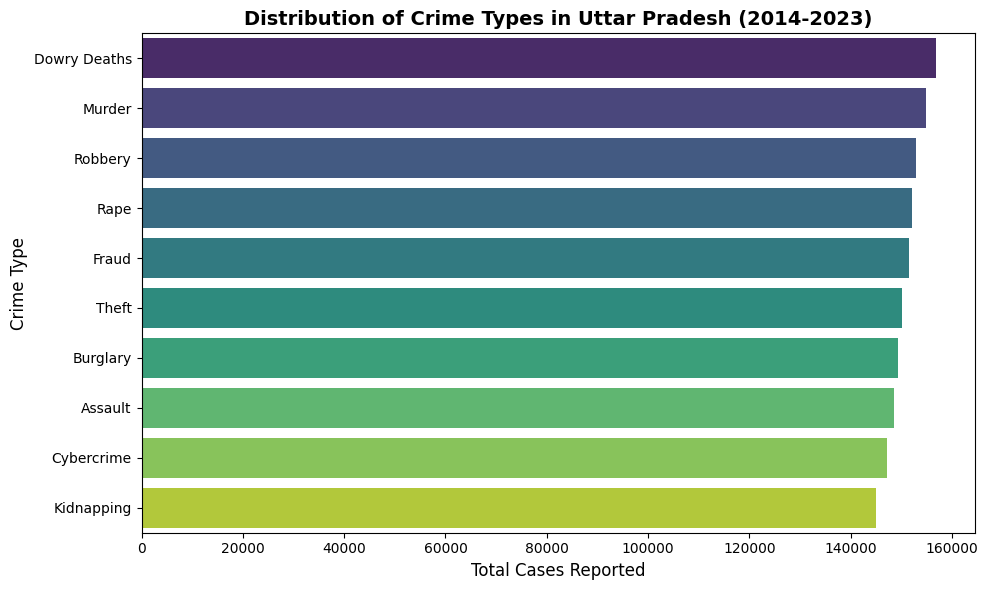

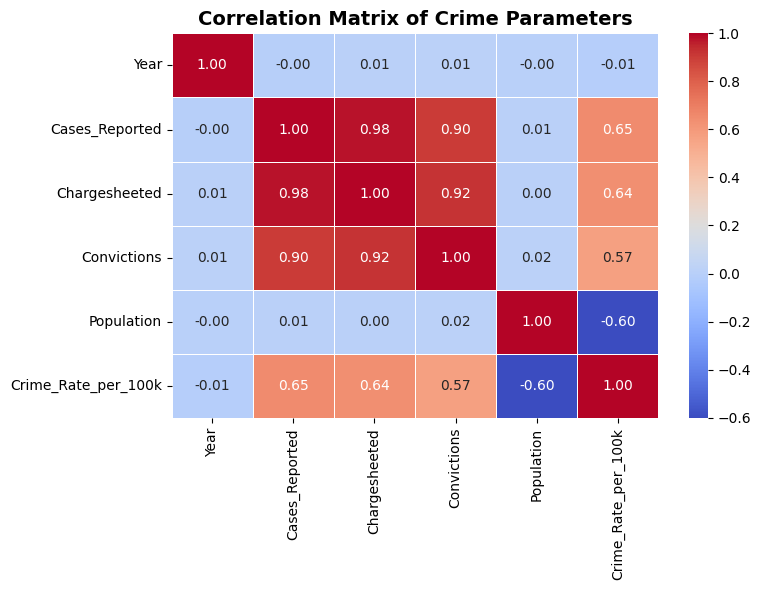

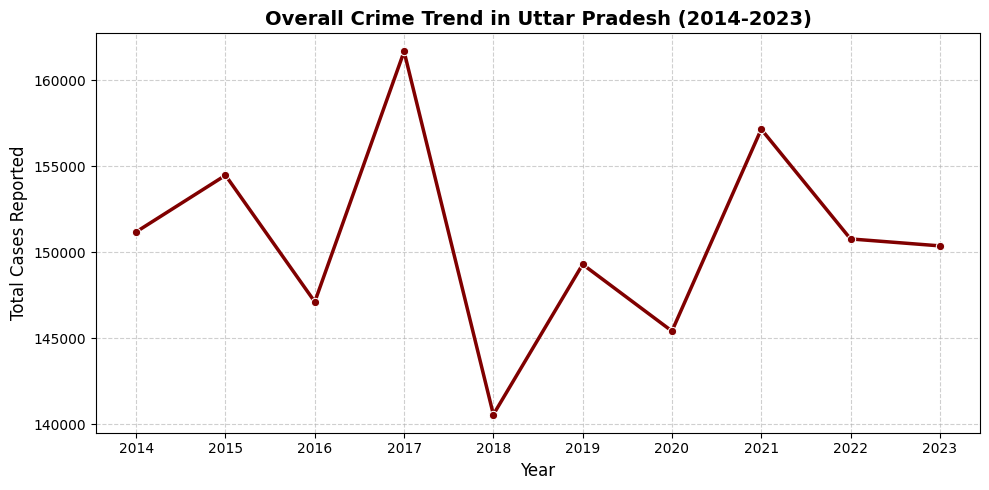

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('india_district_crime_2014_2023_30k.csv')

df_up = df[df['State'] == 'Uttar Pradesh'].copy()

print('Dataset Shape (UP Data):', df_up.shape)
print('\nMissing Values:\n', df_up.isnull().sum())
print('\nDuplicates Found:', df_up.duplicated().sum())

df_up.drop_duplicates(inplace=True)

print('\nSummary Statistics:\n', df_up.describe())

plt.figure(figsize=(10, 6))
crime_counts = df_up.groupby('Crime_Type')['Cases_Reported'].sum().sort_values(ascending=False)
sns.barplot(
    x=crime_counts.values,
    y=crime_counts.index,
    palette='viridis',
    hue=crime_counts.index,
    legend=False,
)
plt.title(
    'Distribution of Crime Types in Uttar Pradesh (2014-2023)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Total Cases Reported', fontsize=12)
plt.ylabel('Crime Type', fontsize=12)
plt.tight_layout()
plt.savefig('crime_type_distribution.png', dpi=300)
plt.show()

plt.figure(figsize=(8, 6))
numeric_cols = [
    'Year',
    'Cases_Reported',
    'Chargesheeted',
    'Convictions',
    'Population',
    'Crime_Rate_per_100k',
]
sns.heatmap(
    df_up[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5
)
plt.title(
    'Correlation Matrix of Crime Parameters', fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()

plt.figure(figsize=(10, 5))
yearly_trend = df_up.groupby('Year')['Cases_Reported'].sum().reset_index()
sns.lineplot(
    data=yearly_trend,
    x='Year',
    y='Cases_Reported',
    marker='o',
    color='maroon',
    linewidth=2.5,
)
plt.title(
    'Overall Crime Trend in Uttar Pradesh (2014-2023)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Cases Reported', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(yearly_trend['Year'])
plt.tight_layout()
plt.savefig('yearly_crime_trend.png', dpi=300)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ncrb = pd.read_csv('NCRB_Table_1A.1.csv')

print("Dataset Shape:", ncrb.shape)
print("\nFirst 5 Rows:")
print(ncrb.head())

print("\nColumn Names:")
print(ncrb.columns)

print("\nData Types:")
print(ncrb.dtypes)

print("\nMissing Values:")
print(ncrb.isnull().sum())

print("\nDuplicate Rows:", ncrb.duplicated().sum())

ncrb = ncrb.drop_duplicates()

ncrb['State/UT'] = ncrb['State/UT'].str.strip()

up_data = ncrb[ncrb['State/UT'] == 'Uttar Pradesh']

print("\nUttar Pradesh Data:")
print(up_data.to_string(index=False))

print("\nUttar Pradesh Shape:", up_data.shape)
print("\nSummary Statistics:")
print(up_data.describe())

Dataset Shape: (39, 8)

First 5 Rows:
  Sl. No.           State/UT    2020    2021    2022  \
0       1     Andhra Pradesh  188997  179611  158547   
1       2  Arunachal Pradesh    2244    2626    2308   
2       3              Assam  111558  119883   59315   
3       4              Bihar  194698  186006  211079   
4       5       Chhattisgarh   65216   70519   73822   

   Mid-Year Projected Population (in Lakhs) (2022)  \
0                                            530.3   
1                                             15.5   
2                                            354.9   
3                                           1255.3   
4                                            299.5   

   Rate of Cognizable Crimes (IPC) (2022)  Chargesheeting Rate (2022)  
0                                   299.0                        86.5  
1                                   148.8                        47.2  
2                                   167.1                        32.6  
3           

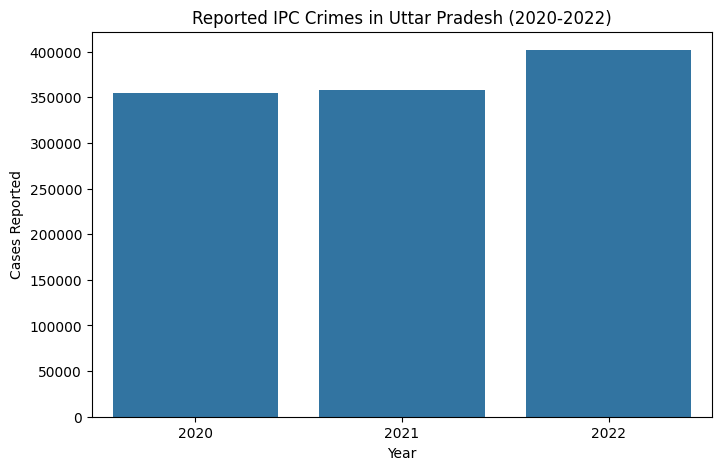

In [ ]:
years = ['2020', '2021', '2022']
crimes = up_data[years].iloc[0]

plt.figure(figsize=(8, 5))
sns.barplot(x=years, y=crimes.values)
plt.title('Reported IPC Crimes in Uttar Pradesh (2020-2022)')
plt.xlabel('Year')
plt.ylabel('Cases Reported')
plt.show()

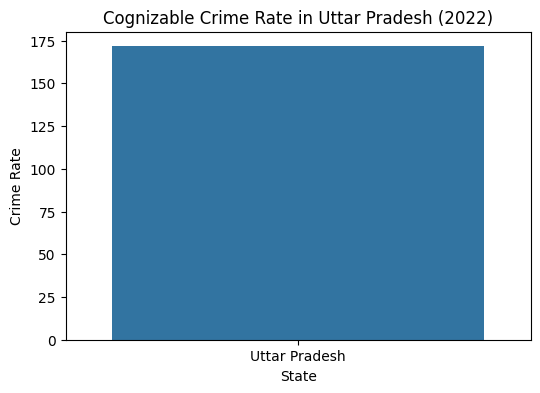

In [ ]:
crime_rate = up_data['Rate of Cognizable Crimes (IPC) (2022)'].iloc[0]

plt.figure(figsize=(6, 4))
sns.barplot(x=['Uttar Pradesh'], y=[crime_rate])
plt.title('Cognizable Crime Rate in Uttar Pradesh (2022)')
plt.xlabel('State')
plt.ylabel('Crime Rate')
plt.show()

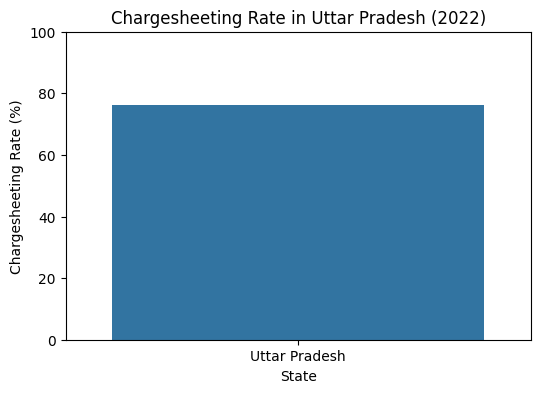

In [ ]:
chargesheeting_rate = up_data['Chargesheeting Rate (2022)'].iloc[0]

plt.figure(figsize=(6, 4))
sns.barplot(x=['Uttar Pradesh'], y=[chargesheeting_rate])
plt.title('Chargesheeting Rate in Uttar Pradesh (2022)')
plt.xlabel('State')
plt.ylabel('Chargesheeting Rate (%)')
plt.ylim(0, 100)
plt.show()

In [ ]:
print("Uttar Pradesh Crime Statistics")

print("Crimes Reported in 2020:", up_data['2020'].iloc[0])
print("Crimes Reported in 2021:", up_data['2021'].iloc[0])
print("Crimes Reported in 2022:", up_data['2022'].iloc[0])

print("Projected Population (2022):",
      up_data['Mid-Year Projected Population (in Lakhs) (2022)'].iloc[0], "Lakhs")

print("Cognizable Crime Rate (2022):", crime_rate)
print("Chargesheeting Rate (2022):", chargesheeting_rate, "%")

Uttar Pradesh Crime Statistics
Crimes Reported in 2020: 355110
Crimes Reported in 2021: 357905
Crimes Reported in 2022: 401787
Projected Population (2022): 2340.9 Lakhs
Cognizable Crime Rate (2022): 171.6
Chargesheeting Rate (2022): 76.1 %


KMEANS & DBSCAN

In [ ]:
import pandas as pd

df = pd.read_csv('india_district_crime_2014_2023_30k.csv')

up = df[df['State'] == 'Uttar Pradesh'].copy()

crime_features = up.pivot_table(
    index='District',
    columns='Crime_Type',
    values='Cases_Reported',
    aggfunc='sum',
    fill_value=0
)

totals = up.groupby('District').agg({
    'Cases_Reported': 'sum',
    'Chargesheeted': 'sum',
    'Convictions': 'sum'
})

population = up.groupby(['District', 'Year'])['Population'].first()
avg_population = population.groupby('District').mean()

district_ml = crime_features.copy()

district_ml['Total_Cases'] = totals['Cases_Reported']
district_ml['Total_Chargesheeted'] = totals['Chargesheeted']
district_ml['Total_Convictions'] = totals['Convictions']
district_ml['Average_Population'] = avg_population

print("ML Dataset Shape:", district_ml.shape)
print("\nDistrict-wise ML Dataset:")
print(district_ml.head())

print("\nMissing Values:")
print(district_ml.isnull().sum())

print("\nNumber of Districts:", district_ml.shape[0])

ML Dataset Shape: (25, 14)

District-wise ML Dataset:
Crime_Type  Assault  Burglary  Cybercrime  Dowry Deaths  Fraud  Kidnapping  \
District                                                                     
Agra           5861      5166        5654          5597   5873        6024   
Aligarh        4459      6456        5484          6604   5833        6213   
Ayodhya        6222      5633        5561          5945   6583        6120   
Ballia         5573      4721        5923          6477   6072        5652   
Bareilly       6167      2311        4690          7255   5893        5495   

Crime_Type  Murder  Rape  Robbery  Theft  Total_Cases  Total_Chargesheeted  \
District                                                                     
Agra          6025  6417     6428   6761        59806                48270   
Aligarh       5960  5971     6963   6104        60047                47673   
Ayodhya       7036  5353     5528   5818        59799                47588   
Ballia   

In [ ]:
years_count = up['Year'].nunique()

ml_features = crime_features.div(
    avg_population, axis=0
) * (100000 / years_count)

ml_features['Chargesheeting_Rate'] = (
    totals['Chargesheeted'] / totals['Cases_Reported']
) * 100

ml_features['Conviction_Rate'] = (
    totals['Convictions'] / totals['Chargesheeted']
) * 100

print("ML Features Shape:", ml_features.shape)
print("\nPrepared Features:")
print(ml_features.head())

print("\nMissing Values:")
print(ml_features.isnull().sum())

print("\nNumber of Years:", years_count)

ML Features Shape: (25, 12)

Prepared Features:
Crime_Type    Assault   Burglary  Cybercrime  Dowry Deaths      Fraud  \
District                                                                
Agra        14.504180  12.784268   13.991919     13.850861  14.533877   
Aligarh     20.659424  29.911918   25.408451     30.597631  27.025437   
Ayodhya     19.226348  17.406303   17.183819     18.370402  20.341859   
Ballia      29.308734  24.828016   31.149404     34.062923  31.933004   
Bareilly    13.718440   5.140800   10.432866     16.138687  13.108930   

Crime_Type  Kidnapping     Murder       Rape    Robbery      Theft  \
District                                                             
Agra         14.907555  14.910030  15.880110  15.907332  16.731405   
Aligarh      28.786051  27.613853  27.664818  32.260949  28.281033   
Ayodhya      18.911162  21.741656  16.541087  17.081847  17.977964   
Ballia       29.724199  38.149211  25.953454  34.083959  37.781077   
Bareilly     12.2235

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(ml_features)

scaled_df = pd.DataFrame(
    scaled_features,
    index=ml_features.index,
    columns=ml_features.columns
)

print("Scaled Dataset Shape:", scaled_df.shape)
print("\nScaled Features:")
print(scaled_df.head())

print("\nFeature Means:")
print(scaled_df.mean().round(2))

print("\nFeature Standard Deviations:")
print(scaled_df.std().round(2))

Scaled Dataset Shape: (25, 12)

Scaled Features:
Crime_Type   Assault  Burglary  Cybercrime  Dowry Deaths     Fraud  \
District                                                             
Agra       -0.541698 -0.690639   -0.585264     -0.680126 -0.536375   
Aligarh    -0.073418  0.658445    0.328029      0.569880  0.277759   
Ayodhya    -0.182444 -0.326578   -0.329920     -0.342780 -0.157842   
Ballia      0.584605  0.258004    0.787290      0.828535  0.597608   
Bareilly   -0.601476 -1.292688   -0.869979     -0.509359 -0.629246   

Crime_Type  Kidnapping    Murder      Rape   Robbery     Theft  \
District                                                         
Agra         -0.509402 -0.546130 -0.442067 -0.513940 -0.374115   
Aligarh       0.657750  0.317547  0.467078  0.884832  0.522026   
Ayodhya      -0.172707 -0.081678 -0.391075 -0.413480 -0.277394   
Ballia        0.736646  1.033800  0.335053  1.040759  1.259138   
Bareilly     -0.735119 -0.717276 -0.536927 -0.801242 -0.714041  

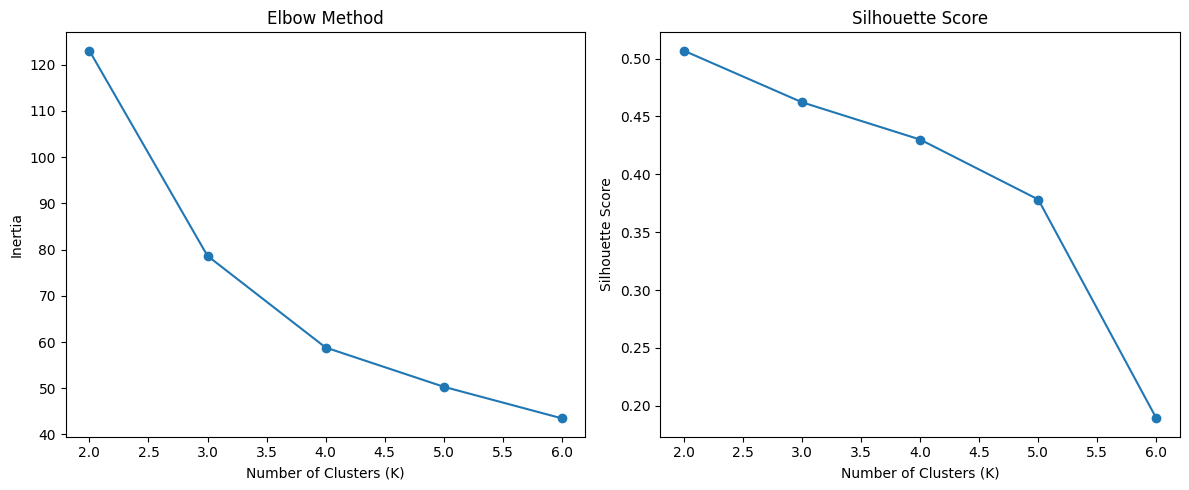

Silhouette Scores: [np.float64(0.5067722244888815), np.float64(0.46220401369708314), np.float64(0.43000913315725625), np.float64(0.37821869981885714), np.float64(0.18915608685639845)]
Best K based on Silhouette Score: 2


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
k_values = range(2, 7)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_features)

    inertia.append(model.inertia_)
    silhouette_scores.append(silhouette_score(scaled_features, labels))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, marker='o')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

best_k = list(k_values)[silhouette_scores.index(max(silhouette_scores))]

print("Silhouette Scores:", silhouette_scores)
print("Best K based on Silhouette Score:", best_k)

In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)

district_ml['KMeans_Cluster'] = kmeans.fit_predict(scaled_features)

print("K-Means Clustering Results:")
print(district_ml[['KMeans_Cluster']].sort_values('KMeans_Cluster'))

print("\nDistricts in Each Cluster:")
print(district_ml['KMeans_Cluster'].value_counts().sort_index())

K-Means Clustering Results:
Crime_Type     KMeans_Cluster
District                     
Agra                        0
Ayodhya                     0
Etawah                      0
Bareilly                    0
Firozabad                   0
Meerut                      0
Mirzapur                    0
Kanpur Nagar                0
Lucknow                     0
Noida                       0
Saharanpur                  0
Sitapur                     0
Raebareli                   0
Moradabad                   0
Muzaffarnagar               0
Basti                       1
Mathura                     1
Ghaziabad                   1
Gorakhpur                   1
Jhansi                      1
Ballia                      1
Aligarh                     1
Prayagraj                   1
Shahjahanpur                1
Varanasi                    1

Districts in Each Cluster:
KMeans_Cluster
0    15
1    10
Name: count, dtype: int64


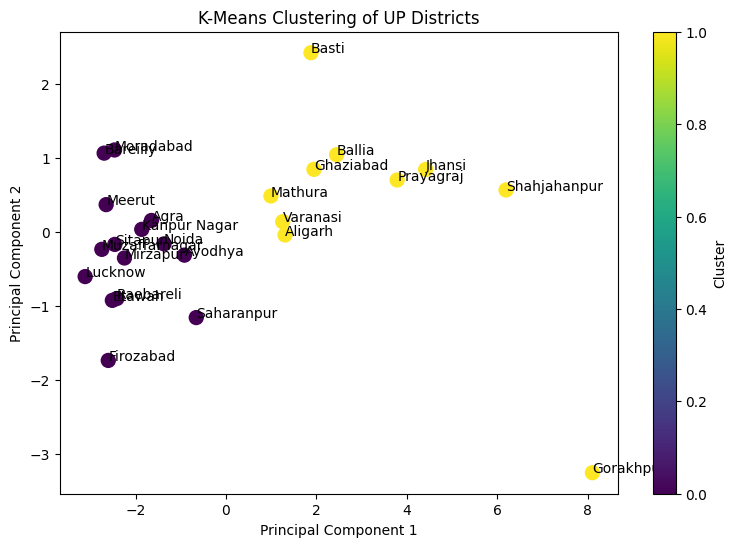

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_features = pca.fit_transform(scaled_features)

plt.figure(figsize=(9, 6))

plt.scatter(
    pca_features[:, 0],
    pca_features[:, 1],
    c=district_ml['KMeans_Cluster'],
    cmap='viridis',
    s=100
)

for i, district in enumerate(district_ml.index):
    plt.annotate(district, (pca_features[i, 0], pca_features[i, 1]))

plt.title('K-Means Clustering of UP Districts')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.show()

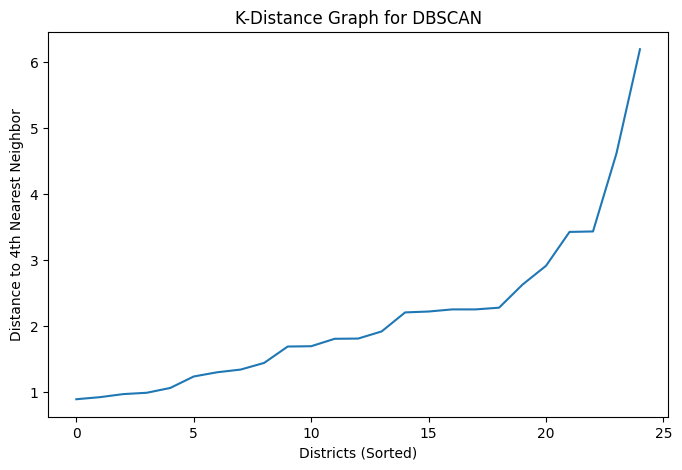

In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

neighbors = NearestNeighbors(n_neighbors=4)
neighbors_fit = neighbors.fit(scaled_features)

distances, indices = neighbors_fit.kneighbors(scaled_features)

distances = np.sort(distances[:, 3])

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-Distance Graph for DBSCAN')
plt.xlabel('Districts (Sorted)')
plt.ylabel('Distance to 4th Nearest Neighbor')
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=4)
    labels = dbscan.fit_predict(scaled_features)

    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = list(labels).count(-1)

    print("Epsilon:", eps)
    print("Number of Clusters:", clusters)
    print("Noise Points:", noise)

    mask = labels != -1

    if clusters >= 2 and mask.sum() > clusters:
        score = silhouette_score(scaled_features[mask], labels[mask])
        print("Silhouette Score:", round(score, 3))
    else:
        print("Silhouette Score: Not applicable")

    print("-----------------------")

Epsilon: 0.5
Number of Clusters: 0
Noise Points: 25
Silhouette Score: Not applicable
-----------------------
Epsilon: 1.0
Number of Clusters: 1
Noise Points: 18
Silhouette Score: Not applicable
-----------------------
Epsilon: 1.5
Number of Clusters: 1
Noise Points: 12
Silhouette Score: Not applicable
-----------------------
Epsilon: 2.0
Number of Clusters: 1
Noise Points: 11
Silhouette Score: Not applicable
-----------------------
Epsilon: 2.5
Number of Clusters: 2
Noise Points: 5
Silhouette Score: 0.52
-----------------------
Epsilon: 3.0
Number of Clusters: 1
Noise Points: 3
Silhouette Score: Not applicable
-----------------------


In [ ]:
results = []

for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=4)
    labels = model.fit_predict(scaled_features)

    clusters = len(set(labels)) - (1 if -1 in labels else 0)
    mask = labels != -1

    if clusters >= 2 and mask.sum() > clusters:
        score = silhouette_score(
            scaled_features[mask],
            labels[mask]
        )
        results.append((eps, score))

if results:
    best_eps = max(results, key=lambda x: x[1])[0]

    dbscan = DBSCAN(eps=best_eps, min_samples=4)
    dbscan_labels = dbscan.fit_predict(scaled_features)

    district_ml['DBSCAN_Cluster'] = dbscan_labels

    print("Selected Epsilon:", best_eps)
    print("\nDBSCAN Results:")
    print(district_ml[['DBSCAN_Cluster']])

    print("\nCluster Distribution:")
    print(district_ml['DBSCAN_Cluster'].value_counts().sort_index())
else:
    print("No valid clustering found. DBSCAN parameters need adjustment.")

Selected Epsilon: 2.5

DBSCAN Results:
Crime_Type     DBSCAN_Cluster
District                     
Agra                        0
Aligarh                     1
Ayodhya                     0
Ballia                      1
Bareilly                    0
Basti                      -1
Etawah                      0
Firozabad                   0
Ghaziabad                   1
Gorakhpur                  -1
Jhansi                     -1
Kanpur Nagar                0
Lucknow                     0
Mathura                     1
Meerut                      0
Mirzapur                    0
Moradabad                   0
Muzaffarnagar               0
Noida                       0
Prayagraj                  -1
Raebareli                   0
Saharanpur                  0
Shahjahanpur               -1
Sitapur                     0
Varanasi                    1

Cluster Distribution:
DBSCAN_Cluster
-1     5
 0    15
 1     5
Name: count, dtype: int64


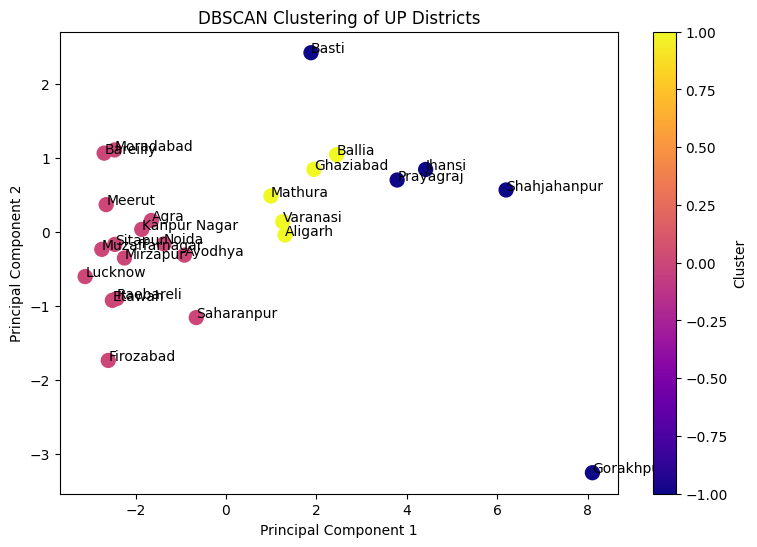

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pca_features[:, 0],
    pca_features[:, 1],
    c=dbscan_labels,
    cmap='plasma',
    s=100
)

for i, district in enumerate(district_ml.index):
    plt.annotate(
        district,
        (pca_features[i, 0], pca_features[i, 1])
    )

plt.title('DBSCAN Clustering of UP Districts')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

kmeans_score = silhouette_score(scaled_features, kmeans.labels_)

dbscan_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

dbscan_mask = dbscan_labels != -1

if dbscan_clusters >= 2 and dbscan_mask.sum() > dbscan_clusters:
    dbscan_score = silhouette_score(
        scaled_features[dbscan_mask],
        dbscan_labels[dbscan_mask]
    )
else:
    dbscan_score = None

comparison = pd.DataFrame({
    'Model': ['K-Means', 'DBSCAN'],
    'Number of Clusters': [best_k, dbscan_clusters],
    'Silhouette Score': [kmeans_score, dbscan_score],
    'Noise Points': [0, list(dbscan_labels).count(-1)]
})

print(comparison)

     Model  Number of Clusters  Silhouette Score  Noise Points
0  K-Means                   2          0.506772             0
1   DBSCAN                   2          0.520271             5


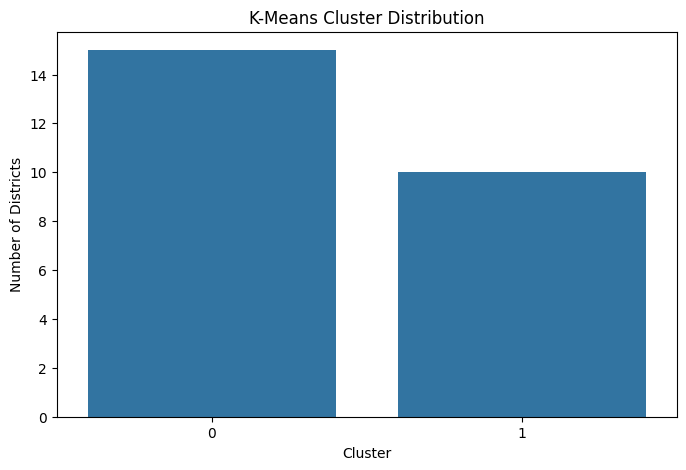

In [ ]:
plt.figure(figsize=(8, 5))

cluster_counts = district_ml['KMeans_Cluster'].value_counts().sort_index()

sns.barplot(x=cluster_counts.index, y=cluster_counts.values)

plt.title('K-Means Cluster Distribution')
plt.xlabel('Cluster')
plt.ylabel('Number of Districts')
plt.show()

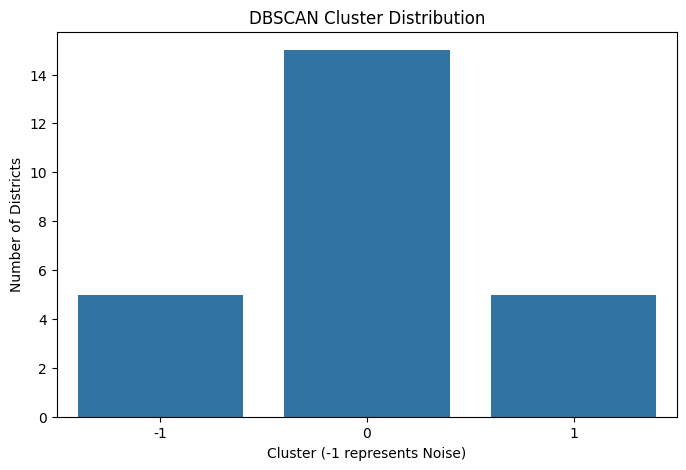

In [ ]:
plt.figure(figsize=(8, 5))

cluster_counts = district_ml['DBSCAN_Cluster'].value_counts().sort_index()

sns.barplot(x=cluster_counts.index.astype(str), y=cluster_counts.values)

plt.title('DBSCAN Cluster Distribution')
plt.xlabel('Cluster (-1 represents Noise)')
plt.ylabel('Number of Districts')
plt.show()

In [ ]:
print("K-Means Cluster Profiles:")

print(
    district_ml.groupby('KMeans_Cluster')[crime_features.columns].mean().round(2)
)

print("\nDistrict-wise Cluster Assignment:")

print(
    district_ml[['KMeans_Cluster', 'DBSCAN_Cluster']].sort_values('KMeans_Cluster')
)

K-Means Cluster Profiles:
Crime_Type      Assault  Burglary  Cybercrime  Dowry Deaths   Fraud  \
KMeans_Cluster                                                        
0               5995.27    5859.2     5893.93       6208.73  5899.4   
1               5854.50    6143.6     5884.20       6366.20  6295.4   

Crime_Type      Kidnapping  Murder     Rape  Robbery    Theft  
KMeans_Cluster                                                 
0                   5853.8  5989.0  6299.33   6151.8  6127.07  
1                   5716.3  6494.8  5754.20   6052.6  5817.70  

District-wise Cluster Assignment:
Crime_Type     KMeans_Cluster  DBSCAN_Cluster
District                                     
Agra                        0               0
Ayodhya                     0               0
Etawah                      0               0
Bareilly                    0               0
Firozabad                   0               0
Meerut                      0               0
Mirzapur                    0 

In [ ]:
district_clusters = district_ml[['KMeans_Cluster']].copy()

print(district_clusters.sort_values('KMeans_Cluster'))

Crime_Type     KMeans_Cluster
District                     
Agra                        0
Ayodhya                     0
Etawah                      0
Bareilly                    0
Firozabad                   0
Meerut                      0
Mirzapur                    0
Kanpur Nagar                0
Lucknow                     0
Noida                       0
Saharanpur                  0
Sitapur                     0
Raebareli                   0
Moradabad                   0
Muzaffarnagar               0
Basti                       1
Mathura                     1
Ghaziabad                   1
Gorakhpur                   1
Jhansi                      1
Ballia                      1
Aligarh                     1
Prayagraj                   1
Shahjahanpur                1
Varanasi                    1


In [ ]:
cluster_analysis = district_ml.groupby('KMeans_Cluster').agg({
    'Total_Cases': 'mean',
    'Total_Chargesheeted': 'mean',
    'Total_Convictions': 'mean'
}).round(2)

print(cluster_analysis)

Crime_Type      Total_Cases  Total_Chargesheeted  Total_Convictions
KMeans_Cluster                                                     
0                  60277.53             48226.53           26663.07
1                  60379.50             48446.50           26472.00


In [ ]:
model_comparison = district_ml[['KMeans_Cluster', 'DBSCAN_Cluster']].copy()

print(model_comparison.sort_values('KMeans_Cluster'))

Crime_Type     KMeans_Cluster  DBSCAN_Cluster
District                                     
Agra                        0               0
Ayodhya                     0               0
Etawah                      0               0
Bareilly                    0               0
Firozabad                   0               0
Meerut                      0               0
Mirzapur                    0               0
Kanpur Nagar                0               0
Lucknow                     0               0
Noida                       0               0
Saharanpur                  0               0
Sitapur                     0               0
Raebareli                   0               0
Moradabad                   0               0
Muzaffarnagar               0               0
Basti                       1              -1
Mathura                     1               1
Ghaziabad                   1               1
Gorakhpur                   1              -1
Jhansi                      1     

In [ ]:
final_results = district_ml.copy()

final_results = final_results.reset_index()

final_results = final_results.rename(columns={
    'index': 'District'
})

print("Final Results Shape:", final_results.shape)
print(final_results.head())

Final Results Shape: (25, 17)
Crime_Type  District  Assault  Burglary  Cybercrime  Dowry Deaths  Fraud  \
0               Agra     5861      5166        5654          5597   5873   
1            Aligarh     4459      6456        5484          6604   5833   
2            Ayodhya     6222      5633        5561          5945   6583   
3             Ballia     5573      4721        5923          6477   6072   
4           Bareilly     6167      2311        4690          7255   5893   

Crime_Type  Kidnapping  Murder  Rape  Robbery  Theft  Total_Cases  \
0                 6024    6025  6417     6428   6761        59806   
1                 6213    5960  5971     6963   6104        60047   
2                 6120    7036  5353     5528   5818        59799   
3                 5652    7254  4935     6481   7184        60272   
4                 5495    5571  6586     5641   5552        55161   

Crime_Type  Total_Chargesheeted  Total_Convictions  Average_Population  \
0                       

In [ ]:
final_results.to_csv('UP_District_Crime_Clustering_Results.csv', index=False)

print("File saved successfully!")

File saved successfully!


PREDICTION & HOTSPOT DETECTION

Prepared Prediction Dataset: (150, 12)
  District  Year  Current_Rate  Previous_Rate  Two_Year_Rate  Three_Year_Rate  \
0     Agra  2017    167.611010     142.171158     155.781974       135.390497   
1     Agra  2018    164.492896     167.611010     142.171158       155.781974   
2     Agra  2019    152.391643     164.492896     167.611010       142.171158   
3     Agra  2020    145.932692     152.391643     164.492896       167.611010   
4     Agra  2021    147.318521     145.932692     152.391643       164.492896   

   Average_Rate  Rate_Change  Current_Cases  Population  Target_Year  \
0    155.188047    25.439852           6773     4040904         2018   
1    158.091688    -3.118114           6647     4040904         2019   
2    161.498516   -12.101253           6158     4040904         2020   
3    154.272410    -6.458951           5897     4040904         2021   
4    148.547619     1.385829           5953     4040904         2022   

   Target_Rate  
0   164.492896  
1   152

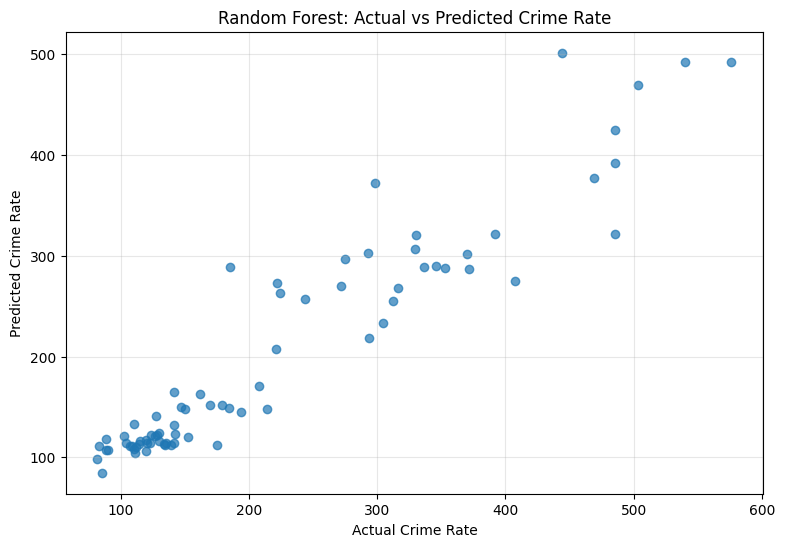


FUTURE CRIME HOTSPOT PREDICTIONS
     District  Predicted_Crime_Rate    Hotspot_Status
    Gorakhpur            467.675221 Predicted Hotspot
 Shahjahanpur            466.239611 Predicted Hotspot
    Prayagraj            408.482668 Predicted Hotspot
       Jhansi            407.456792 Predicted Hotspot
        Basti            316.038954 Predicted Hotspot
       Ballia            289.901255 Predicted Hotspot
    Ghaziabad            278.000523 Predicted Hotspot
      Aligarh            276.395771    Other District
     Varanasi            241.694260    Other District
      Mathura            236.639848    Other District
      Ayodhya            178.025367    Other District
        Noida            156.839418    Other District
   Saharanpur            151.312105    Other District
     Bareilly            135.359922    Other District
         Agra            134.322571    Other District
 Kanpur Nagar            130.545291    Other District
    Moradabad            129.172290    Other Dis

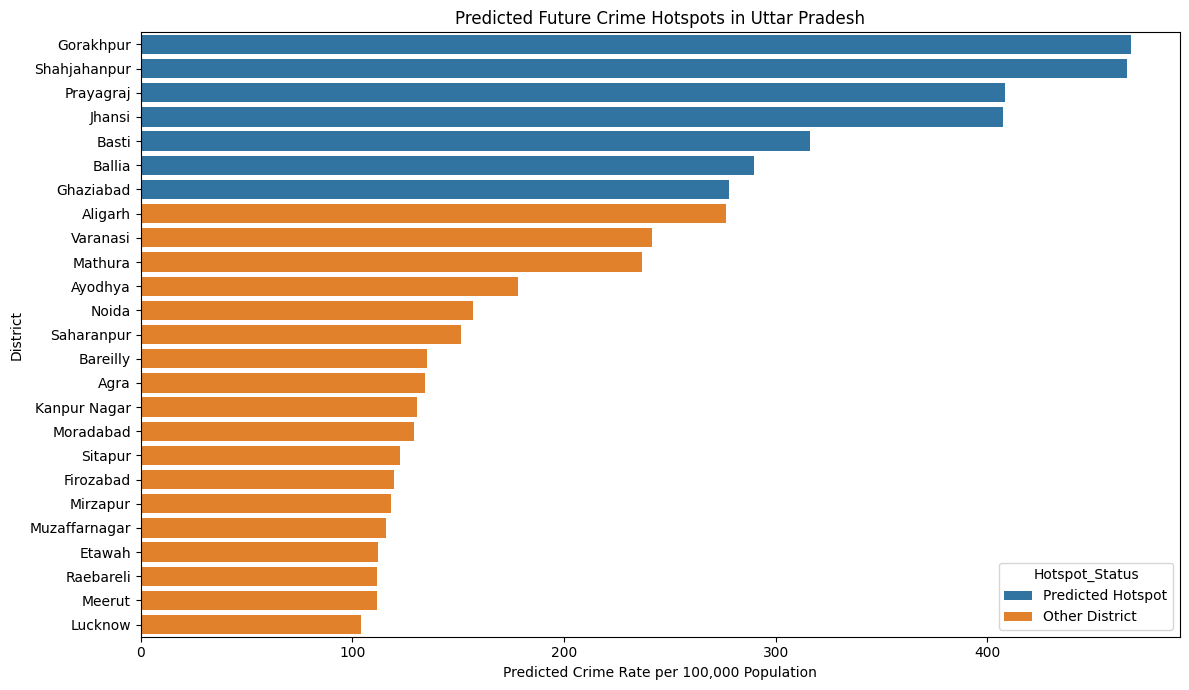


Future prediction file saved successfully!


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load Uttar Pradesh data
up = pd.read_csv('india_district_crime_2014_2023_30k.csv')
up = up[up['State'] == 'Uttar Pradesh'].copy()

# Aggregate crime data district-wise and year-wise
yearly = up.groupby(['District', 'Year']).agg(
    Cases_Reported=('Cases_Reported', 'sum'),
    Population=('Population', 'first')
).reset_index()

yearly['Crime_Rate'] = (
    yearly['Cases_Reported'] / yearly['Population']
) * 100000

yearly = yearly.sort_values(['District', 'Year'])

# Prepare historical features and next-year target
records = []

for district, group in yearly.groupby('District'):

    group = group.sort_values('Year').set_index('Year')

    for year in group.index:

        if all(y in group.index for y in [year-1, year-2, year-3, year+1]):

            current = group.loc[year]
            previous = group.loc[year-1]
            previous2 = group.loc[year-2]
            previous3 = group.loc[year-3]
            future = group.loc[year+1]

            records.append({
                'District': district,
                'Year': year,
                'Current_Rate': current['Crime_Rate'],
                'Previous_Rate': previous['Crime_Rate'],
                'Two_Year_Rate': previous2['Crime_Rate'],
                'Three_Year_Rate': previous3['Crime_Rate'],
                'Average_Rate': np.mean([
                    current['Crime_Rate'],
                    previous['Crime_Rate'],
                    previous2['Crime_Rate']
                ]),
                'Rate_Change': current['Crime_Rate'] - previous['Crime_Rate'],
                'Current_Cases': current['Cases_Reported'],
                'Population': current['Population'],
                'Target_Year': year + 1,
                'Target_Rate': future['Crime_Rate']
            })

model_data = pd.DataFrame(records)

print("Prepared Prediction Dataset:", model_data.shape)
print(model_data.head())

# Chronological train-test split
train = model_data[model_data['Target_Year'] <= 2020]
test = model_data[model_data['Target_Year'] > 2020]

features = [
    'District',
    'Year',
    'Current_Rate',
    'Previous_Rate',
    'Two_Year_Rate',
    'Three_Year_Rate',
    'Average_Rate',
    'Rate_Change',
    'Current_Cases',
    'Population'
]

X_train = train[features]
y_train = train['Target_Rate']

X_test = test[features]
y_test = test['Target_Rate']

# Encode district and train Random Forest
preprocessor = ColumnTransformer(
    transformers=[
        ('district', OneHotEncoder(handle_unknown='ignore'), ['District'])
    ],
    remainder='passthrough'
)

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=2,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

# Evaluate model
predictions = rf_model.predict(X_test)

print("\nRANDOM FOREST EVALUATION")
print("MAE:", round(mean_absolute_error(y_test, predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 3))
print("R2 Score:", round(r2_score(y_test, predictions), 3))

# Compare with previous-year baseline
baseline = test['Current_Rate']

print("\nBASELINE MAE:", round(mean_absolute_error(y_test, baseline), 3))

# Actual vs predicted graph
plt.figure(figsize=(9, 6))
plt.scatter(y_test, predictions, alpha=0.7)
plt.xlabel('Actual Crime Rate')
plt.ylabel('Predicted Crime Rate')
plt.title('Random Forest: Actual vs Predicted Crime Rate')
plt.grid(alpha=0.3)
plt.show()

# Prepare next-year prediction using latest available year
future_records = []

for district, group in yearly.groupby('District'):

    group = group.sort_values('Year').set_index('Year')
    latest_year = group.index.max()

    if all(y in group.index for y in [
        latest_year,
        latest_year-1,
        latest_year-2
    ]):

        current = group.loc[latest_year]
        previous = group.loc[latest_year-1]
        previous2 = group.loc[latest_year-2]

        future_records.append({
            'District': district,
            'Year': latest_year,
            'Current_Rate': current['Crime_Rate'],
            'Previous_Rate': previous['Crime_Rate'],
            'Two_Year_Rate': previous2['Crime_Rate'],
            'Three_Year_Rate': previous2['Crime_Rate'],
            'Average_Rate': np.mean([
                current['Crime_Rate'],
                previous['Crime_Rate'],
                previous2['Crime_Rate']
            ]),
            'Rate_Change': current['Crime_Rate'] - previous['Crime_Rate'],
            'Current_Cases': current['Cases_Reported'],
            'Population': current['Population']
        })

future_data = pd.DataFrame(future_records)

future_data['Predicted_Crime_Rate'] = rf_model.predict(
    future_data[features]
)

# Identify predicted hotspots
future_data['Hotspot_Status'] = np.where(
    future_data['Predicted_Crime_Rate'] >=
    future_data['Predicted_Crime_Rate'].quantile(0.75),
    'Predicted Hotspot',
    'Other District'
)

future_data = future_data.sort_values(
    'Predicted_Crime_Rate',
    ascending=False
)

print("\nFUTURE CRIME HOTSPOT PREDICTIONS")
print(
    future_data[
        ['District', 'Predicted_Crime_Rate', 'Hotspot_Status']
    ].to_string(index=False)
)

# Visualize predicted hotspots
plt.figure(figsize=(12, 7))

sns.barplot(
    data=future_data,
    x='Predicted_Crime_Rate',
    y='District',
    hue='Hotspot_Status',
    dodge=False
)

plt.title('Predicted Future Crime Hotspots in Uttar Pradesh')
plt.xlabel('Predicted Crime Rate per 100,000 Population')
plt.ylabel('District')
plt.tight_layout()
plt.show()

# Save prediction results
future_data.to_csv(
    'UP_Future_Crime_Hotspot_Predictions.csv',
    index=False
)

print("\nFuture prediction file saved successfully!")


In [ ]:
yearly_data = (
    up.groupby(['District', 'Year'])
    .agg({
        'Cases_Reported': 'sum',
        'Population': 'mean'
    })
    .reset_index()
)

yearly_data['Crime_Rate'] = (
    yearly_data['Cases_Reported'] /
    yearly_data['Population']
) * 100000

print("Yearly dataset shape:", yearly_data.shape)
display(yearly_data.head())


future_records = []

for district, group in yearly_data.groupby('District'):

    group = group.sort_values('Year').set_index('Year')

    if not all(year in group.index for year in [2020, 2021, 2022, 2023]):
        continue

    current = group.loc[2023]
    previous = group.loc[2022]
    previous2 = group.loc[2021]
    previous3 = group.loc[2020]

    future_records.append({
        'District': district,
        'Year': 2023,
        'Current_Rate': current['Crime_Rate'],
        'Previous_Rate': previous['Crime_Rate'],
        'Two_Year_Rate': previous2['Crime_Rate'],
        'Three_Year_Rate': previous3['Crime_Rate'],
        'Average_Rate': (
            current['Crime_Rate'] +
            previous['Crime_Rate'] +
            previous2['Crime_Rate'] +
            previous3['Crime_Rate']
        ) / 4,
        'Rate_Change': current['Crime_Rate'] - previous['Crime_Rate'],
        'Current_Cases': current['Cases_Reported'],
        'Population': current['Population'],
        'Target_Year': 2024
    })

future_df = pd.DataFrame(future_records)

future_features = future_df[[
    'District', 'Year', 'Current_Rate',
    'Previous_Rate', 'Two_Year_Rate',
    'Three_Year_Rate', 'Average_Rate',
    'Rate_Change', 'Current_Cases', 'Population'
]]

future_df['Predicted_Crime_Rate'] = rf_model.predict(future_features)

threshold = future_df['Predicted_Crime_Rate'].quantile(0.75)

future_df['Hotspot_Status'] = future_df[
    'Predicted_Crime_Rate'
].apply(
    lambda x: 'Predicted Hotspot' if x >= threshold else 'Other District'
)

future_df = future_df.sort_values(
    'Predicted_Crime_Rate', ascending=False
)

print("2024 CRIME HOTSPOT PREDICTIONS")
display(future_df[[
    'District',
    'Predicted_Crime_Rate',
    'Hotspot_Status'
]])

future_df.to_csv(
    'UP_2024_Crime_Hotspot_Predictions.csv',
    index=False
)

print("2024 predictions saved successfully!")


Yearly dataset shape: (250, 5)


,District,Year,Cases_Reported,Population,Crime_Rate
0,Agra,2014,5471,4040904.0,135.390497
1,Agra,2015,6295,4040904.0,155.781974
2,Agra,2016,5745,4040904.0,142.171158
3,Agra,2017,6773,4040904.0,167.611010
4,Agra,2018,6647,4040904.0,164.492896


2024 CRIME HOTSPOT PREDICTIONS


,District,Predicted_Crime_Rate,Hotspot_Status
9,Gorakhpur,485.818393,Predicted Hotspot
22,Shahjahanpur,453.354490,Predicted Hotspot
19,Prayagraj,327.026882,Predicted Hotspot
10,Jhansi,324.748927,Predicted Hotspot
5,Basti,308.960046,Predicted Hotspot
3,Ballia,285.791495,Predicted Hotspot
8,Ghaziabad,262.509503,Predicted Hotspot
1,Aligarh,261.261126,Other District
24,Varanasi,240.616177,Other District
13,Mathura,235.046834,Other District


2024 predictions saved successfully!


In [ ]:

high_threshold = future_df['Predicted_Crime_Rate'].quantile(0.75)
moderate_threshold = future_df['Predicted_Crime_Rate'].quantile(0.50)

def classify_risk(rate):
    if rate >= high_threshold:
        return 'High Risk'
    elif rate >= moderate_threshold:
        return 'Moderate Risk'
    else:
        return 'Low Risk'

future_df['Risk_Level'] = future_df['Predicted_Crime_Rate'].apply(classify_risk)

future_df = future_df.sort_values(
    'Predicted_Crime_Rate', ascending=False
)

print("2024 DISTRICT-WISE CRIME RISK PREDICTIONS")

display(future_df[[
    'District',
    'Predicted_Crime_Rate',
    'Risk_Level'
]])

print("\nRISK CATEGORY COUNTS")
display(future_df['Risk_Level'].value_counts())


2024 DISTRICT-WISE CRIME RISK PREDICTIONS


,District,Predicted_Crime_Rate,Risk_Level
9,Gorakhpur,485.818393,High Risk
22,Shahjahanpur,453.354490,High Risk
19,Prayagraj,327.026882,High Risk
10,Jhansi,324.748927,High Risk
5,Basti,308.960046,High Risk
3,Ballia,285.791495,High Risk
8,Ghaziabad,262.509503,High Risk
1,Aligarh,261.261126,Moderate Risk
24,Varanasi,240.616177,Moderate Risk
13,Mathura,235.046834,Moderate Risk



RISK CATEGORY COUNTS


,count
Risk_Level,
Low Risk,12
High Risk,7
Moderate Risk,6


In [ ]:

final_predictions = future_df[[
    'District',
    'Predicted_Crime_Rate',
    'Risk_Level'
]].copy()

final_predictions.to_csv(
    'UP_2024_Crime_Hotspot_Predictions.csv',
    index=False
)

print("Final prediction dataset saved!")
print("\nRisk category distribution:")
display(final_predictions['Risk_Level'].value_counts())

display(final_predictions)


Final prediction dataset saved!

Risk category distribution:


,count
Risk_Level,
Low Risk,12
High Risk,7
Moderate Risk,6


,District,Predicted_Crime_Rate,Risk_Level
9,Gorakhpur,485.818393,High Risk
22,Shahjahanpur,453.354490,High Risk
19,Prayagraj,327.026882,High Risk
10,Jhansi,324.748927,High Risk
5,Basti,308.960046,High Risk
3,Ballia,285.791495,High Risk
8,Ghaziabad,262.509503,High Risk
1,Aligarh,261.261126,Moderate Risk
24,Varanasi,240.616177,Moderate Risk
13,Mathura,235.046834,Moderate Risk


DASHBOARD

In [ ]:
import pandas as pd

crime_data = pd.read_csv('/content/india_district_crime_2014_2023_30k.csv')
prediction_data = pd.read_csv('/content/UP_2024_Crime_Hotspot_Predictions.csv')
cluster_data = pd.read_csv('/content/UP_District_Crime_Clustering_Results.csv')


In [ ]:

# FILTER UTTAR PRADESH DATA

up_dashboard = crime_data[
    crime_data['State'].str.strip().str.lower() == 'uttar pradesh'
].copy()

# DISTRICT-WISE STATISTICS

district_summary = (
    up_dashboard.groupby('District')
    .agg(
        Total_Crimes=('Cases_Reported', 'sum'),
        Chargesheeted=('Chargesheeted', 'sum'),
        Convictions=('Convictions', 'sum')
    )
    .reset_index()
)

# CRIME CATEGORY STATISTICS

crime_categories = (
    up_dashboard.groupby('Crime_Type')['Cases_Reported']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# OVERALL STATISTICS

total_crimes = up_dashboard['Cases_Reported'].sum()
total_chargesheeted = up_dashboard['Chargesheeted'].sum()
total_convictions = up_dashboard['Convictions'].sum()

print("UP DASHBOARD DATA READY")
print("Total districts:", district_summary['District'].nunique())
print("Total crimes:", total_crimes)
print("Total chargesheeted:", total_chargesheeted)
print("Total convictions:", total_convictions)

print("\nDISTRICT SUMMARY")
display(district_summary.head())

print("\nCRIME CATEGORIES")
display(crime_categories)


UP DASHBOARD DATA READY
Total districts: 25
Total crimes: 1507958
Total chargesheeted: 1207863
Total convictions: 664666

DISTRICT SUMMARY


,District,Total_Crimes,Chargesheeted,Convictions
0,Agra,59806,48270,26311
1,Aligarh,60047,47673,26833
2,Ayodhya,59799,47588,26600
3,Ballia,60272,49079,26340
4,Bareilly,55161,44399,25831



CRIME CATEGORIES


,Crime_Type,Cases_Reported
0,Dowry Deaths,156793
1,Murder,154783
2,Robbery,152803
3,Rape,152032
4,Fraud,151445
5,Theft,150083
6,Burglary,149324
7,Assault,148474
8,Cybercrime,147251
9,Kidnapping,144970


In [ ]:

# COMBINE DISTRICT DATA

district_dashboard = district_summary.merge(
    prediction_data,
    on='District',
    how='left'
)

district_dashboard = district_dashboard.merge(
    cluster_data[['District', 'KMeans_Cluster', 'DBSCAN_Cluster']],
    on='District',
    how='left'
)

# CALCULATE RATES

district_dashboard['Chargesheeting_Rate'] = (
    district_dashboard['Chargesheeted'] /
    district_dashboard['Total_Crimes']
) * 100

district_dashboard['Conviction_Rate'] = (
    district_dashboard['Convictions'] /
    district_dashboard['Total_Crimes']
) * 100

district_dashboard = district_dashboard.sort_values(
    'Total_Crimes', ascending=False
)

print("DISTRICT DASHBOARD DATA READY")
print("Total districts:", len(district_dashboard))
display(district_dashboard.head(10))


DISTRICT DASHBOARD DATA READY
Total districts: 25


,District,Total_Crimes,Chargesheeted,Convictions,Predicted_Crime_Rate,Risk_Level,KMeans_Cluster,DBSCAN_Cluster,Chargesheeting_Rate,Conviction_Rate
14,Meerut,65233,52562,29156,114.065446,Low Risk,0,0,80.575782,44.695170
11,Kanpur Nagar,64525,52008,28146,135.013996,Low Risk,0,0,80.601317,43.620302
8,Ghaziabad,64329,51561,29124,262.509503,High Risk,1,1,80.152031,45.273516
6,Etawah,63209,50173,27729,116.522905,Low Risk,0,0,79.376355,43.868753
22,Shahjahanpur,63104,50416,27920,453.354490,High Risk,1,-1,79.893509,44.244422
20,Raebareli,62926,49925,27546,110.838864,Low Risk,0,0,79.339224,43.775228
13,Mathura,61536,49601,27068,235.046834,Moderate Risk,1,1,80.604849,43.987259
23,Sitapur,60975,48807,27078,117.679095,Low Risk,0,0,80.044280,44.408364
18,Noida,60934,49087,26485,156.839418,Moderate Risk,0,0,80.557653,43.465061
19,Prayagraj,60763,48954,26865,327.026882,High Risk,1,-1,80.565476,44.212761


In [ ]:

# SAVE DASHBOARD DATASETS

up_dashboard.to_csv(
    '/content/UP_Crime_Data.csv',
    index=False
)

district_dashboard.to_csv(
    '/content/UP_District_Dashboard.csv',
    index=False
)

crime_categories.to_csv(
    '/content/UP_Crime_Categories.csv',
    index=False
)

# YEAR-WISE CRIME SUMMARY

yearly_summary = (
    up_dashboard.groupby('Year')
    .agg(
        Total_Crimes=('Cases_Reported', 'sum'),
        Chargesheeted=('Chargesheeted', 'sum'),
        Convictions=('Convictions', 'sum')
    )
    .reset_index()
)

yearly_summary.to_csv(
    '/content/UP_Yearly_Summary.csv',
    index=False
)

print("ALL DASHBOARD DATASETS SAVED!")



ALL DASHBOARD DATASETS SAVED!


In [ ]:
import requests
import json

url = "https://raw.githubusercontent.com/datta07/INDIAN-SHAPEFILES/master/STATES/UTTAR%20PRADESH/UTTAR%20PRADESH_DISTRICTS.geojson"

response = requests.get(url)
response.raise_for_status()

with open('/content/UP_Districts.geojson', 'w') as f:
    f.write(response.text)

geo_data = response.json()

print("Map downloaded successfully!")
print("Number of district boundaries:", len(geo_data['features']))
print("District properties:")
print(geo_data['features'][0]['properties'])

Map downloaded successfully!
Number of district boundaries: 75
District properties:
{'dtname': 'Amroha', 'stname': 'UTTAR PRADESH', 'stcode11': '09', 'dtcode11': '137', 'year_stat': '2011_c', 'Shape_Length': 397787.0031263654, 'Shape_Area': 2824405492.1886363, 'OBJECTID': 195, 'test': 0, 'Dist_LGD': 154, 'State_LGD': 9}


In [ ]:
!pip install flask pandas plotly

In [ ]:
import os
import shutil

source = "/content/app.py"
destination = "/content/app.py"

if os.path.exists(source):
    print("Final dashboard app.py is already in place!")
else:
    print("app.py not found. Please upload it.")

Final dashboard app.py is already in place!


In [ ]:
%%writefile app.py
from flask import Flask, jsonify, render_template_string
import pandas as pd
import json
import math
import re

app = Flask(__name__)

# ------------------------------------------------------------
# LOAD THE EXISTING PROJECT FILES
# ------------------------------------------------------------
BASE = '/content/'

crime_data = pd.read_csv(BASE + 'UP_Crime_Data.csv')
district_data = pd.read_csv(BASE + 'UP_District_Dashboard.csv')
category_data = pd.read_csv(BASE + 'UP_Crime_Categories.csv')
yearly_data = pd.read_csv(BASE + 'UP_Yearly_Summary.csv')
prediction_data = pd.read_csv(BASE + 'UP_2024_Crime_Hotspot_Predictions.csv')
clustering_data = pd.read_csv(BASE + 'UP_District_Crime_Clustering_Results.csv')

with open(BASE + 'UP_Districts.geojson', 'r', encoding='utf-8') as geo_file:
    geo_data = json.load(geo_file)


def clean_name(value):
    """Normalize district names so CSV and GeoJSON spellings can match."""
    value = str(value).strip().lower()
    value = re.sub(r'\bdistrict\b', '', value)
    value = re.sub(r'[^a-z0-9]+', ' ', value)
    return ' '.join(value.split())


# Known differences between the district CSV and the boundary GeoJSON.
ALIASES = {
    'faizabad': 'ayodhya',
    'gautam buddha nagar': 'noida',
    'rae bareli': 'raebareli',
    'rae bareli district': 'raebareli',
    'allahabad': 'prayagraj'
}


def canonical_name(value):
    key = clean_name(value)
    return ALIASES.get(key, key)


# Join the district summary, model predictions and clustering results.
district_data['join_key'] = district_data['District'].map(canonical_name)
prediction_data['join_key'] = prediction_data['District'].map(canonical_name)
clustering_data['join_key'] = clustering_data['District'].map(canonical_name)

if 'Predicted_Crime_Rate' in district_data.columns:
    district_data = district_data.drop(columns=['Predicted_Crime_Rate'], errors='ignore')
if 'Risk_Level' in district_data.columns:
    district_data = district_data.drop(columns=['Risk_Level'], errors='ignore')

district_data = district_data.merge(
    prediction_data[['join_key', 'Predicted_Crime_Rate', 'Risk_Level']],
    on='join_key', how='left'
)

cluster_columns = [
    col for col in clustering_data.columns
    if col not in district_data.columns and col != 'District'
]
district_data = district_data.merge(
    clustering_data[['join_key'] + cluster_columns],
    on='join_key', how='left'
)

# Keep a stable display order and lookup for the browser.
district_data = district_data.sort_values('District').reset_index(drop=True)
district_lookup = {
    canonical_name(row['District']): row.to_dict()
    for _, row in district_data.iterrows()
}


def safe_records(frame):
    """Convert dataframe rows to JSON-safe Python values."""
    safe = frame.copy()
    safe = safe.astype(object).where(pd.notna(safe), None)
    return safe.to_dict(orient='records')


def as_number(value, default=0):
    try:
        number = float(value)
        if math.isfinite(number):
            return number
    except (TypeError, ValueError):
        pass
    return default


# ------------------------------------------------------------
# API ROUTES
# ------------------------------------------------------------
@app.route('/')
def home():
    return render_template_string(DASHBOARD)


@app.route('/api/summary')
def api_summary():
    predicted = pd.to_numeric(district_data['Predicted_Crime_Rate'], errors='coerce').dropna()
    population = pd.to_numeric(district_data.get('Average_Population', pd.Series(dtype=float)), errors='coerce')
    rates = pd.to_numeric(district_data['Predicted_Crime_Rate'], errors='coerce')

    valid = rates.notna()
    if valid.any() and len(population) == len(rates) and population[valid].fillna(0).sum() > 0:
        overall_rate = float((rates[valid] * population[valid].fillna(0)).sum() / population[valid].fillna(0).sum())
    elif len(predicted):
        overall_rate = float(predicted.mean())
    else:
        overall_rate = 0.0

    risk_counts = district_data['Risk_Level'].fillna('Not available').value_counts().to_dict()

    return jsonify({
        'total_crimes': int(pd.to_numeric(crime_data['Cases_Reported'], errors='coerce').fillna(0).sum()),
        'chargesheeted': int(pd.to_numeric(crime_data['Chargesheeted'], errors='coerce').fillna(0).sum()),
        'convictions': int(pd.to_numeric(crime_data['Convictions'], errors='coerce').fillna(0).sum()),
        'districts': int(district_data['District'].nunique()),
        'overall_predicted_rate': overall_rate,
        'predicted_districts': int(predicted.count()),
        'high_risk_districts': int(risk_counts.get('High Risk', 0)),
        'risk_counts': risk_counts
    })


@app.route('/api/map')
def api_map():
    features = []
    for original in geo_data.get('features', []):
        feature = dict(original)
        props = dict(original.get('properties', {}))
        geo_name = props.get('dtname') or props.get('DISTRICT') or props.get('district') or 'Unknown'
        record = district_lookup.get(canonical_name(geo_name))
        props['total_crimes'] = as_number(record.get('Total_Crimes'), None) if record else None
        props['has_data'] = record is not None
        props['dashboard_district'] = record.get('District') if record else None
        props['risk_level'] = record.get('Risk_Level') if record else None
        feature['properties'] = props
        features.append(feature)
    return jsonify({'type': 'FeatureCollection', 'features': features})


@app.route('/api/districts')
def api_districts():
    cols = [
        'District', 'Total_Crimes', 'Chargesheeted', 'Convictions',
        'Predicted_Crime_Rate', 'Risk_Level', 'KMeans_Cluster',
        'DBSCAN_Cluster', 'Chargesheeting_Rate', 'Conviction_Rate'
    ]
    cols = [c for c in cols if c in district_data.columns]
    result = district_data[cols].sort_values('Total_Crimes', ascending=False)
    return jsonify(safe_records(result))


@app.route('/api/categories')
def api_categories():
    return jsonify(safe_records(category_data))


@app.route('/api/yearly')
def api_yearly():
    return jsonify(safe_records(yearly_data))


@app.route('/api/district/<district_name>')
def api_district(district_name):
    key = canonical_name(district_name)
    record = district_lookup.get(key)
    if not record:
        return jsonify({'error': 'District data is not available.'}), 404

    # Also provide the crime-category counts from the clustering dataset.
    category_fields = [
        'Assault', 'Burglary', 'Cybercrime', 'Dowry Deaths', 'Fraud',
        'Kidnapping', 'Murder', 'Rape', 'Robbery', 'Theft'
    ]
    category_values = [
        {'Crime_Type': col, 'Cases_Reported': as_number(record.get(col), 0)}
        for col in category_fields if col in record
    ]
    cleaned = {k: (None if pd.isna(v) else v) if not isinstance(v, (dict, list)) else v
               for k, v in record.items() if k != 'join_key'}
    return jsonify({'district': cleaned, 'crime_categories': category_values})


# ------------------------------------------------------------
# ONE-PAGE DASHBOARD: OVERVIEW + COMBINED DISTRICT ANALYSIS / PREDICTION + ABOUT
# ------------------------------------------------------------
DASHBOARD = r"""
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>UP Crime Analytics</title>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
:root{--bg:#F8F5EF;--paper:#FFFDF9;--sidebar:#EAE2D5;--ink:#514A43;--muted:#897D70;--rose:#B77B72;--rose2:#D9AAA0;--green:#AAB99C;--line:#E8E0D7;--tan:#D8B99A;--shadow:0 3px 14px rgba(70,50,35,.06)}
*{box-sizing:border-box}html{scroll-behavior:smooth;scroll-padding-top:22px}body{margin:0;background:var(--bg);color:var(--ink);font-family:Arial, sans-serif}
.sidebar{position:fixed;inset:0 auto 0 0;width:238px;background:var(--sidebar);padding:28px 18px;z-index:1000;overflow-y:auto;border-right:1px solid #e2d8ca}
.brand{font-size:20px;font-weight:700;line-height:1.35;margin:0 8px 32px}.brand small{display:block;font-size:11px;font-weight:400;color:var(--muted);letter-spacing:1.3px;text-transform:uppercase;margin-top:5px}
.nav-label{font-size:10px;text-transform:uppercase;letter-spacing:1.5px;color:#9A8C7D;margin:22px 10px 8px}.nav-link{display:block;text-decoration:none;color:#62584E;padding:12px 13px;border-radius:10px;margin:5px 0;font-size:14px;cursor:pointer}.nav-link:hover,.nav-link.active{background:#FFFDF9;color:#514238;box-shadow:0 2px 8px #60452a0b}
.main{margin-left:238px;padding:32px 34px 60px;max-width:1600px}.page-section{margin-bottom:42px;scroll-margin-top:20px}.page-head{margin-bottom:22px}.page-head h1{font-size:29px;margin:0 0 8px}.subtitle{color:var(--muted);font-size:14px;line-height:1.6}.section-title{font-size:21px;margin:0 0 8px}.section-subtitle{font-size:13px;color:var(--muted);margin:0 0 18px;line-height:1.5}
.cards{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:16px;margin:22px 0}.metric,.panel{background:var(--paper);border:1px solid var(--line);border-radius:15px;box-shadow:var(--shadow)}.metric{padding:19px 20px}.metric .label{font-size:12px;color:var(--muted);margin-bottom:12px}.metric .value{font-size:27px;font-weight:700;letter-spacing:-.5px}.metric .hint{font-size:11px;color:#9B8E82;margin-top:7px}.panel{padding:21px;margin-bottom:19px}.panel h3{font-size:16px;margin:0 0 14px}.grid-2{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:18px}.grid-3{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:14px}.chart{height:330px;min-width:0}#map{height:540px;width:100%;border-radius:11px;background:#EEE9E1;z-index:1}.map-legend{display:flex;gap:14px;flex-wrap:wrap;margin-top:13px;font-size:11px;color:var(--muted)}.legend-dot{display:inline-block;width:10px;height:10px;border-radius:3px;margin-right:5px;vertical-align:middle}
.select-wrap{display:flex;gap:12px;align-items:center;flex-wrap:wrap;margin:10px 0 18px}.select-wrap label{font-size:13px;font-weight:700}.select-wrap select{min-width:240px;max-width:100%;padding:12px 14px;border:1px solid #DCCFC1;border-radius:9px;background:#fffdf9;color:var(--ink);font-size:14px;outline:none}.select-wrap select:focus{border-color:var(--rose)}.empty-state{padding:28px;text-align:center;color:var(--muted);background:#FBF8F2;border:1px dashed #DCCFC1;border-radius:12px;line-height:1.6}.detail-grid{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:12px;margin:16px 0}.detail-stat{background:#FBF8F2;border:1px solid var(--line);padding:15px;border-radius:11px}.detail-stat span{display:block;color:var(--muted);font-size:11px;margin-bottom:8px}.detail-stat strong{font-size:20px}.risk-pill{display:inline-block;border-radius:20px;padding:6px 11px;font-size:12px;font-weight:700;background:#E8EBDD;color:#526448}.risk-high{background:#F1DFDA;color:#8D4F45}.risk-moderate{background:#F4E8D8;color:#8B6846}.risk-low{background:#E8EBDD;color:#526448}.note{font-size:12px;color:var(--muted);line-height:1.6}.about-grid{display:grid;grid-template-columns:1.2fr 1fr;gap:18px}.about-list{padding-left:18px;line-height:1.9;color:#6E6257;font-size:13px}.footer{border-top:1px solid var(--line);padding-top:18px;margin-top:35px;color:#9A8E82;font-size:11px}
@media(max-width:1100px){.sidebar{width:205px}.main{margin-left:205px;padding:25px 22px}.cards{grid-template-columns:repeat(2,minmax(0,1fr))}.detail-grid{grid-template-columns:repeat(2,minmax(0,1fr))}}
@media(max-width:760px){.sidebar{position:relative;width:100%;height:auto;padding:14px;display:flex;align-items:center;gap:6px;flex-wrap:wrap}.brand{width:100%;margin:0 8px 8px}.brand small{display:inline;margin-left:6px}.nav-label{display:none}.nav-link{padding:9px 10px;margin:0;font-size:12px}.main{margin:0;padding:20px 14px 45px}.grid-2,.about-grid{grid-template-columns:1fr}.cards{grid-template-columns:repeat(2,minmax(0,1fr));gap:10px}.metric{padding:15px}.metric .value{font-size:21px}.page-head h1{font-size:24px}#map{height:420px}.chart{height:290px}.detail-grid{grid-template-columns:repeat(2,minmax(0,1fr))}}
</style>
</head>
<body>
<aside class="sidebar">
  <div class="brand">🌷 UP Crime Analytics<small>Statistical ML Project</small></div>
  <div class="nav-label">Dashboard</div>
  <a class="nav-link active" href="#overview" data-section="overview">⌂ &nbsp; Overview</a>
  <a class="nav-link" href="#district-analysis" data-section="district-analysis">▦ &nbsp; District Analysis &amp; Prediction</a>
  <a class="nav-link" href="#about" data-section="about">ⓘ &nbsp; About Project</a>
</aside>

<main class="main">
<section id="overview" class="page-section">
  <div class="page-head"><h1>Uttar Pradesh Crime Dashboard</h1><div class="subtitle">Explore district-level crime patterns, case outcomes and machine-learning insights across Uttar Pradesh.<br>Historical dataset coverage: 2014–2023</div></div>
  <div class="cards">
    <div class="metric"><div class="label">Districts Analysed</div><div class="value" id="districtCount">—</div><div class="hint">Districts available in the analysis dataset</div></div>
    <div class="metric"><div class="label">Reported Cases</div><div class="value" id="totalCrimes">—</div><div class="hint">Total recorded cases in the selected dataset</div></div>
    <div class="metric"><div class="label">Chargesheeted Cases</div><div class="value" id="chargesheeted">—</div><div class="hint">Cases with chargesheet filed</div></div>
    <div class="metric"><div class="label">Convictions</div><div class="value" id="convictions">—</div><div class="hint">Recorded convictions</div></div>
  </div>
  <div class="panel"><h3>Uttar Pradesh — District Crime Map</h3><p class="section-subtitle">Hover over a district to view its reported crime count and risk category. Click a district to open its combined analysis and prediction below.</p><div id="map"></div><div class="map-legend"><span><i class="legend-dot" style="background:#754B3A"></i>Higher reported crime count</span><span><i class="legend-dot" style="background:#C99B77"></i>Mid-range reported crime count</span><span><i class="legend-dot" style="background:#E7CDB0"></i>Lower reported crime count</span><span><i class="legend-dot" style="background:#D8D2C9"></i>No district data</span></div></div>
  <div class="grid-2">
    <div class="panel"><h3>Yearly Crime Trend</h3><div id="yearlyChart" class="chart"></div></div>
    <div class="panel"><h3>Crime Categories</h3><div id="categoryChart" class="chart"></div></div>
    <div class="panel"><h3>District-wise Crime Comparison</h3><div id="districtChart" class="chart"></div></div>
    <div class="panel"><h3>Predicted Risk Distribution</h3><div id="riskChart" class="chart"></div></div>
  </div>
  <div class="panel"><h3>Uttar Pradesh — Overall Prediction</h3><p class="section-subtitle">A summary of the district-level model predictions. The displayed rate is a population-weighted average where population data is available.</p>
    <div class="detail-grid">
      <div class="detail-stat"><span>Overall Predicted Crime Rate</span><strong id="overallPrediction">—</strong><div class="note">per 100,000 population</div></div>
      <div class="detail-stat"><span>Districts with Predictions</span><strong id="predictedDistricts">—</strong></div>
      <div class="detail-stat"><span>High-Risk Districts</span><strong id="highRiskDistricts">—</strong></div>
      <div class="detail-stat"><span>Prediction Coverage</span><strong id="predictionCoverage">—</strong></div>
    </div>
    <div class="note">These are model-generated estimates based on the available historical dataset, not confirmed future crime counts.</div>
  </div>
</section>

<section id="district-analysis" class="page-section">
  <div class="page-head"><h1>District Analysis &amp; Crime Prediction</h1><div class="subtitle">Historical crime statistics, case outcomes, clustering and predicted risk are shown together for the selected district.</div></div>
  <div class="panel">
    <h3>Select a District</h3>
    <div class="select-wrap"><label for="districtSelect">District</label><select id="districtSelect"><option value="">Choose a district…</option></select><span class="note">You can also click a district directly on the map.</span></div>
    <div id="districtEmpty" class="empty-state">Select a district from the dropdown or click one on the map to view its complete analysis and prediction.</div>
    <div id="districtContent" hidden>
      <div style="display:flex;align-items:center;gap:12px;flex-wrap:wrap;margin:8px 0 4px"><h2 id="selectedDistrictName" style="margin:0;font-size:23px"></h2><span id="selectedRisk" class="risk-pill"></span></div>
      <p class="section-subtitle">Historical performance and machine-learning results for this district.</p>
      <div class="detail-grid">
        <div class="detail-stat"><span>Total Reported Crimes</span><strong id="dTotal">—</strong></div>
        <div class="detail-stat"><span>Chargesheeted Cases</span><strong id="dChargesheeted">—</strong></div>
        <div class="detail-stat"><span>Convictions</span><strong id="dConvictions">—</strong></div>
        <div class="detail-stat"><span>Predicted Crime Rate</span><strong id="dPrediction">—</strong><div class="note">per 100,000 population</div></div>
        <div class="detail-stat"><span>Chargesheeting Rate</span><strong id="dChargeRate">—</strong></div>
        <div class="detail-stat"><span>Conviction Rate</span><strong id="dConvictionRate">—</strong></div>
        <div class="detail-stat"><span>K-Means Cluster</span><strong id="dKmeans">—</strong></div>
        <div class="detail-stat"><span>DBSCAN Cluster</span><strong id="dDbscan">—</strong></div>
      </div>
      <div class="grid-2">
        <div class="panel"><h3>Crime Category Breakdown</h3><div id="districtCrimeChart" class="chart"></div></div>
        <div class="panel"><h3>Prediction &amp; Model Interpretation</h3><div id="districtPredictionText" class="note" style="font-size:14px;line-height:1.9"></div></div>
      </div>
    </div>
  </div>
</section>

<section id="about" class="page-section">
  <div class="page-head"><h1>About the Project</h1><div class="subtitle">Crime Hotspot and Pattern Detection Using Machine Learning — Uttar Pradesh</div></div>
  <div class="about-grid">
    <div class="panel"><h3>Project Overview</h3><p class="note" style="font-size:14px">This project analyses district-level crime patterns in Uttar Pradesh using statistical analysis and machine-learning techniques. It brings historical crime information, district comparisons, hotspot predictions and clustering results together in one interactive dashboard.</p><h3 style="margin-top:24px">Project Objectives</h3><ul class="about-list"><li>Explore crime patterns across districts and years.</li><li>Compare reported cases, chargesheeting and convictions.</li><li>Identify groups of districts with similar crime patterns.</li><li>Estimate district-level crime rates and highlight predicted hotspots.</li><li>Present the findings through an interactive map and dashboard.</li></ul></div>
    <div class="panel"><h3>Datasets Used</h3><ul class="about-list"><li>India District Level Crime Dataset (2014–2023) — district-level historical analysis and mapping.</li><li>NCRB Table 1A.1 — supplementary crime statistics used in the project workflow.</li></ul><h3 style="margin-top:24px">Methods &amp; Technologies</h3><ul class="about-list"><li>Python, Pandas and NumPy for data handling.</li><li>Exploratory Data Analysis for understanding distributions and patterns.</li><li>K-Means and DBSCAN for district clustering.</li><li>Random Forest Regression for crime-rate prediction.</li><li>Flask, Leaflet and Plotly for the interactive dashboard.</li></ul></div>
  </div>
  <div class="panel"><h3>How to Read the Predictions</h3><p class="note" style="font-size:14px">Predicted crime rate is a model estimate expressed per 100,000 population. Risk labels are categories assigned in the project's prediction dataset. K-Means and DBSCAN cluster numbers identify groups produced by the respective clustering algorithms; the numbers themselves are labels, not rankings. Predictions should be interpreted as analytical estimates rather than certainty about future events.</p></div>
  <div class="footer">UP Crime Analytics · Statistical Machine Learning Project · Uttar Pradesh</div>
</section>
</main>

<script>
const fmt = n => (n === null || n === undefined || n === '' || !Number.isFinite(Number(n))) ? '—' : Number(n).toLocaleString('en-IN', {maximumFractionDigits:2});
const fmtRate = n => (n === null || n === undefined || !Number.isFinite(Number(n))) ? '—' : Number(n).toFixed(2);
const palette = ['#B77B72','#D9AAA0','#AAB99C','#D8B99A','#9D8778','#C5B8A7','#879B83','#E1C9B2','#A66E51','#C7A7A0'];
let districtRows = [];
let districtChartReady = false;

async function getJSON(url){const response=await fetch(url);if(!response.ok)throw new Error('Could not load '+url);return await response.json();}
function plotLayout(extra={}){return Object.assign({margin:{t:12,r:12,b:45,l:55},paper_bgcolor:'#FFFDF9',plot_bgcolor:'#FFFDF9',font:{family:'Arial',color:'#62584E',size:11}},extra);}

async function loadSummary(){
 const d=await getJSON('/api/summary');
 document.getElementById('districtCount').textContent=fmt(d.districts);
 document.getElementById('totalCrimes').textContent=fmt(d.total_crimes);
 document.getElementById('chargesheeted').textContent=fmt(d.chargesheeted);
 document.getElementById('convictions').textContent=fmt(d.convictions);
 document.getElementById('overallPrediction').textContent=fmtRate(d.overall_predicted_rate);
 document.getElementById('predictedDistricts').textContent=fmt(d.predicted_districts);
 document.getElementById('highRiskDistricts').textContent=fmt(d.high_risk_districts);
 document.getElementById('predictionCoverage').textContent=d.districts ? (100*d.predicted_districts/d.districts).toFixed(1)+'%' : '—';
}

async function loadMap(){
 const geo=await getJSON('/api/map');
 const map=L.map('map',{scrollWheelZoom:false});
 L.tileLayer('https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png',{maxZoom:12,attribution:'&copy; OpenStreetMap'}).addTo(map);
 const values=geo.features.map(f=>f.properties.total_crimes).filter(v=>v!==null && Number.isFinite(Number(v)));
 const max=Math.max(...values,1);
 function color(v){if(v===null)return '#D8D2C9';const r=Number(v)/max;if(r>=.75)return '#754B3A';if(r>=.5)return '#A66E51';if(r>=.25)return '#C99B77';return '#E7CDB0';}
 const layer=L.geoJSON(geo,{style:f=>({fillColor:color(f.properties.total_crimes),weight:1,color:'#FFFFFF',opacity:1,fillOpacity:.82}),onEachFeature:(f,l)=>{
   const p=f.properties;const n=p.dashboard_district||p.dtname||'District';
   const count=p.total_crimes===null?'No data available':fmt(p.total_crimes)+' reported crimes';
   const risk=p.risk_level?' · '+p.risk_level:'';
   l.bindTooltip('<b>'+n+'</b><br>'+count+risk,{sticky:true});
   l.on('mouseover',e=>e.target.setStyle({weight:2.5,color:'#514238',fillOpacity:1}));
   l.on('mouseout',e=>layer.resetStyle(e.target));
   l.on('click',()=>{if(p.has_data && p.dashboard_district){selectDistrict(p.dashboard_district,true);}else{document.getElementById('district-analysis').scrollIntoView({behavior:'smooth'});document.getElementById('districtEmpty').textContent='No district-level records are available for '+(p.dtname||'this district')+' in the selected analysis dataset.';}});
 }}).addTo(map);
 if(layer.getBounds().isValid())map.fitBounds(layer.getBounds(),{padding:[10,10]});
}

async function loadCharts(){
 const yearly=await getJSON('/api/yearly');
 Plotly.newPlot('yearlyChart',[{x:yearly.map(d=>d.Year),y:yearly.map(d=>d.Total_Crimes),type:'scatter',mode:'lines+markers',line:{color:'#A66E51',width:3},marker:{color:'#B77B72',size:7}}],plotLayout({yaxis:{title:'Reported cases',gridcolor:'#EEE8E0'},xaxis:{title:'Year',gridcolor:'#EEE8E0'}}),{responsive:true,displayModeBar:false});
 const categories=await getJSON('/api/categories');
 Plotly.newPlot('categoryChart',[{labels:categories.map(d=>d.Crime_Type),values:categories.map(d=>d.Cases_Reported),type:'pie',hole:.43,marker:{colors:palette},textinfo:'label+percent',textposition:'inside'}],plotLayout({showlegend:false,margin:{t:8,b:8,l:8,r:8}}),{responsive:true,displayModeBar:false});
 districtRows=await getJSON('/api/districts');
 const top=districtRows.slice(0,15).reverse();
 Plotly.newPlot('districtChart',[{x:top.map(d=>d.Total_Crimes),y:top.map(d=>d.District),type:'bar',orientation:'h',marker:{color:'#B88A6A'}}],plotLayout({margin:{t:8,b:35,l:115,r:12},xaxis:{title:'Reported crimes',gridcolor:'#EEE8E0'}}),{responsive:true,displayModeBar:false});
 const risks={};districtRows.forEach(d=>{const r=d.Risk_Level||'Not available';risks[r]=(risks[r]||0)+1;});
 const riskColors=Object.keys(risks).map(r=>r==='High Risk'?'#B77B72':r==='Moderate Risk'?'#D8B99A':r==='Low Risk'?'#AAB99C':'#C9C1B7');
 Plotly.newPlot('riskChart',[{labels:Object.keys(risks),values:Object.values(risks),type:'pie',hole:.45,marker:{colors:riskColors},textinfo:'label+value'}],plotLayout({showlegend:true,margin:{t:8,b:8,l:8,r:8}}),{responsive:true,displayModeBar:false});
 const select=document.getElementById('districtSelect');
 [...districtRows].sort((a,b)=>a.District.localeCompare(b.District)).forEach(d=>{const o=document.createElement('option');o.value=d.District;o.textContent=d.District;select.appendChild(o);});
}

function riskClass(r){if(r==='High Risk')return 'risk-pill risk-high';if(r==='Moderate Risk')return 'risk-pill risk-moderate';return 'risk-pill risk-low';}
async function selectDistrict(name,scroll){
 if(!name)return;
 document.getElementById('districtSelect').value=name;
 const data=await getJSON('/api/district/'+encodeURIComponent(name));
 const d=data.district;
 document.getElementById('districtEmpty').hidden=true;
 document.getElementById('districtContent').hidden=false;
 document.getElementById('selectedDistrictName').textContent=d.District;
 const risk=document.getElementById('selectedRisk');risk.textContent=d.Risk_Level||'Risk not available';risk.className=riskClass(d.Risk_Level);
 document.getElementById('dTotal').textContent=fmt(d.Total_Crimes);
 document.getElementById('dChargesheeted').textContent=fmt(d.Chargesheeted);
 document.getElementById('dConvictions').textContent=fmt(d.Convictions);
 document.getElementById('dPrediction').textContent=fmtRate(d.Predicted_Crime_Rate);
 document.getElementById('dChargeRate').textContent=fmtRate(d.Chargesheeting_Rate)+'%';
 document.getElementById('dConvictionRate').textContent=fmtRate(d.Conviction_Rate)+'%';
 document.getElementById('dKmeans').textContent=d.KMeans_Cluster===null?'—':d.KMeans_Cluster;
 document.getElementById('dDbscan').textContent=d.DBSCAN_Cluster===null?'—':d.DBSCAN_Cluster;
 const cats=data.crime_categories||[];
 Plotly.react('districtCrimeChart',[{x:cats.map(x=>x.Cases_Reported),y:cats.map(x=>x.Crime_Type),type:'bar',orientation:'h',marker:{color:palette}}],plotLayout({margin:{t:8,b:35,l:115,r:12},xaxis:{title:'Cases reported',gridcolor:'#EEE8E0'}}),{responsive:true,displayModeBar:false});
 const predictionText=document.getElementById('districtPredictionText');
 const rate=Number(d.Predicted_Crime_Rate);
 let explanation='The model prediction is not available for this district.';
 if(Number.isFinite(rate)) explanation='The model estimates a crime rate of <b>'+rate.toFixed(2)+'</b> per 100,000 population. The assigned risk category is <b>'+ (d.Risk_Level||'not available') +'</b>. This is a model-based estimate derived from historical patterns, not a confirmed future count.';
 predictionText.innerHTML=explanation+'<br><br><b>K-Means cluster:</b> '+(d.KMeans_Cluster??'Not available')+'<br><b>DBSCAN cluster:</b> '+(d.DBSCAN_Cluster??'Not available')+'. Cluster identifiers represent algorithmic group labels, not severity rankings.';
 if(scroll)document.getElementById('district-analysis').scrollIntoView({behavior:'smooth'});
}

document.getElementById('districtSelect').addEventListener('change',e=>selectDistrict(e.target.value,false));

// Highlight the sidebar item for the section currently in view.
const navLinks=[...document.querySelectorAll('.nav-link')];
const observer=new IntersectionObserver(entries=>{entries.forEach(entry=>{if(entry.isIntersecting){navLinks.forEach(a=>a.classList.toggle('active',a.dataset.section===entry.target.id));}});},{rootMargin:'-20% 0px -65% 0px'});
document.querySelectorAll('.page-section').forEach(section=>observer.observe(section));

(async function init(){
 try{await loadSummary();await loadCharts();await loadMap();}
 catch(err){console.error(err);alert('Dashboard data could not be loaded. Check that all project CSV files and UP_Districts.geojson are present in /content.');}
})();
</script>
</body>
</html>
"""


if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5007, debug=False)

Overwriting app.py


In [ ]:
!python app.py

 * Serving Flask app 'app'
 * Debug mode: off
Address already in use
Port 5007 is in use by another program. Either identify and stop that program, or start the server with a different port.


In [ ]:
!fuser -k 5007/tcp 2>/dev/null
!nohup python -c "import sys; sys.path.insert(0, '/content'); from app import app; app.run(host='0.0.0.0', port=5007, debug=False)" > /content/flask5007.log 2>&1 &

  7487

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(5007)")
print(url)

https://5007-m-s-use1d10-3dpok207zpgsi-d.us-east1.prod.r.colab.dev
